<a href="https://colab.research.google.com/github/Mathivani19/Fundamentals-of-Data-Science-CS23334/blob/main/Mathivani_S_250701418_CSE_Experiment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

         Date    Product  Sales  Quantity Region
0  01-02-2023  Product D    275         5  South
1  02-02-2023  Product A    185         3  North
2  03-02-2023  Product C    315         7   East
3  04-02-2023  Product B    165         4   West
4  05-02-2023  Product D    290         6  South
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
            Sales  Quantity
count   16.000000  16.00000
mean   254.062500   5.50000
std     66.413321   1.75119
min    165.000000   3.00000
25%    192.500000   4.00000
50%    250.000000   5.00000
75%    311.250000   7.00000
max    355.000000   9.00000
     Product  Sales  Quantity
0  Product A    830        17
1  Product B    720        16
2  Product C   1340        31
3  Product D   1175        24


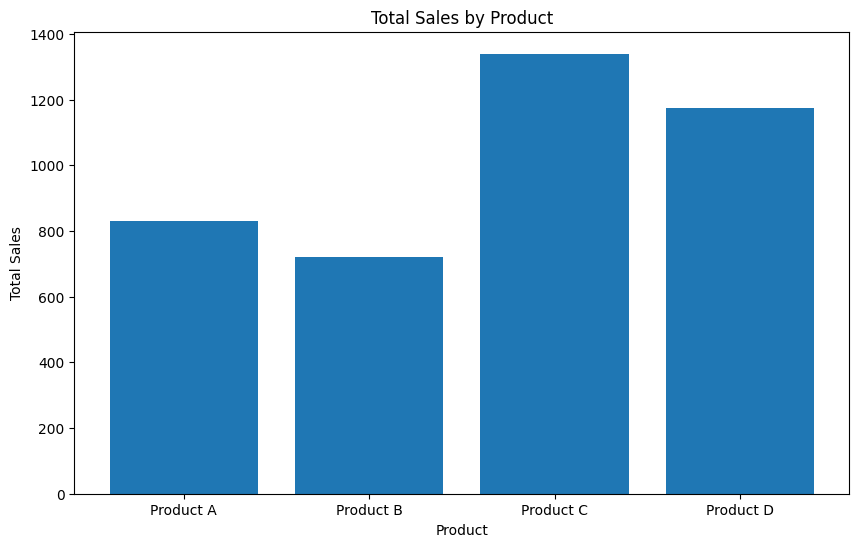

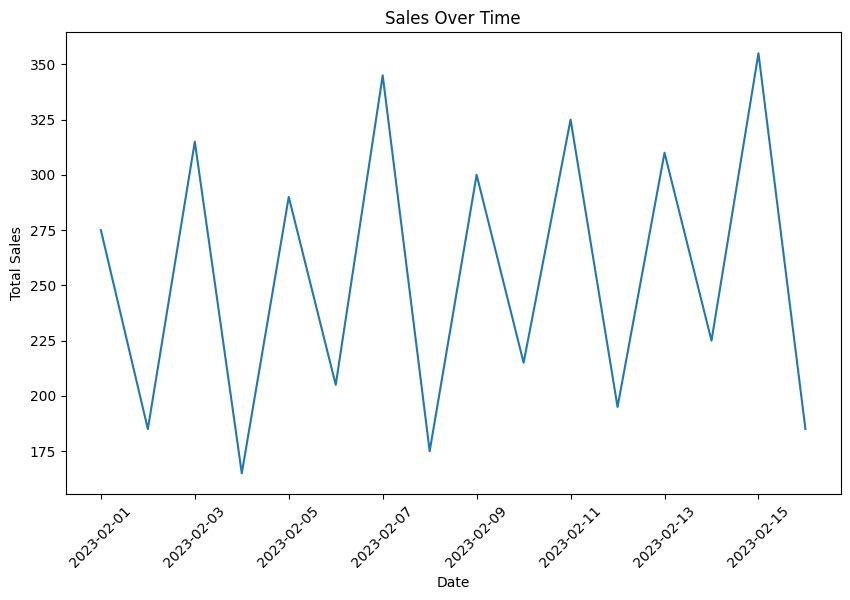

Product  Product A  Product B  Product C  Product D
Region                                             
East             0          0       1340          0
North          830          0          0          0
South            0          0          0       1175
West             0        720          0          0
             Sales  Quantity
Sales     1.000000  0.932913
Quantity  0.932913  1.000000


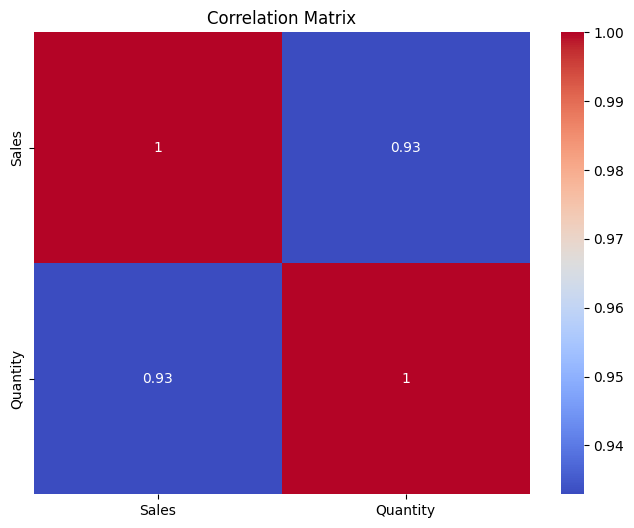

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = 'sales-data-new.csv'
df = pd.read_csv(file_path)

# Display first five rows
print(df.head())

# Check for missing values
print(df.isnull().sum())

# Fill missing Sales values with mean
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())

# Drop rows with missing important values
df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True)

# Summary statistics
print(df.describe())

# Group by Product and calculate total Sales and Quantity
product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

print(product_summary)

# Bar plot of total sales by product
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

# Convert Date into datetime format
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Line plot of sales over time
sales_over_time = df.groupby('Date').agg({
    'Sales': 'sum'
}).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.xticks(rotation=45)
plt.show()

# Pivot table to analyze sales by Region and Product
pivot_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Product',
    aggfunc='sum',
    fill_value=0
)

print(pivot_table)

# Correlation matrix
correlation_matrix = df[['Sales', 'Quantity']].corr()

print(correlation_matrix)

# Heatmap of correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

